# Project 2, Step 4: Holdout test of the inventory policy

**Question:** the Excel tool sets each SKU's reorder point to hit a 95% cycle service level. Does the policy actually deliver 95% on 13 weeks of demand it never saw?

This notebook replays the holdout quarter (2016-02-20 to 2016-05-14, the same quarter as Project 1) week by week for all 2,717 SKUs. It recomputes the policy from the same inputs and formulas as the workbook, then measures what service level the policy achieved.

**Why test a policy on a holdout?** A safety stock formula is a model. It assumes forecast errors are normal, independent, and stable over time. A planner should check the policy against real demand before trusting the dollar numbers it produces.

In [1]:
from pathlib import Path
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

STORE_ID = "CA_1"
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
FIG_DIR = PROJECT_DIR / "outputs" / "figures"

# Base case assumptions, same values as the Excel Assumptions sheet
LEAD_TIME = 1          # L: weeks from placing an order to receiving it
REVIEW = 1             # R: weeks between inventory reviews (store orders once a week)
CSL_TARGET = 0.95      # target cycle service level
UNIT_COST_PCT = 0.70   # unit cost C = 70% of last training shelf price
HOLD_RATE = 0.25       # h: annual holding cost as a share of unit cost
ORDER_COST = 5.0       # S: dollars per SKU order
MAX_WEEKS = 4          # Wmax: order size cap, weeks of average demand
z = NormalDist().inv_cdf(CSL_TARGET)

inputs = pd.read_csv(DATA_DIR / f"sku_policy_inputs_{STORE_ID}.csv")
holdout = pd.read_csv(DATA_DIR / f"holdout_demand_{STORE_ID}.csv")

# Demand matrix: one row per SKU (same order as inputs), one column per holdout week
demand = (holdout.pivot(index="item_id", columns="wm_yr_wk", values="units")
          .loc[inputs["item_id"]].to_numpy(float))
n_sku, n_weeks = demand.shape
print(f"{n_sku:,} SKUs x {n_weeks} weeks, z = {z:.3f}")

2,717 SKUs x 13 weeks, z = 1.645


## 1. Rebuild the workbook policy in Python

Same formulas as the Excel SKU_Policy sheet (base case uses the moving average forecast error):
- $\bar{d}$ = average weekly demand over the last 52 training weeks (the planning forecast)
- $\sigma_1$ = RMSE of the 1-week-ahead moving average forecast (from notebook 01)
- $SS = z \cdot \sigma_1 \sqrt{L}$, $ROP = \bar{d} \cdot L + SS$
- $C$ = unit cost, $H = h \cdot C$ = annual holding cost per unit, $D = 52 \bar{d}$ = annual demand
- $EOQ = \sqrt{2DS/H}$, order quantity $Q = \min(EOQ,\ W_{max} \cdot \bar{d})$

The check at the end confirms the Python policy matches the workbook total ($53,939 of safety stock at 95%).

In [2]:
d = inputs["avg_weekly_demand"].to_numpy()
sigma1 = inputs["rmse_ma"].to_numpy()
C = UNIT_COST_PCT * inputs["last_train_price"].to_numpy()
H = HOLD_RATE * C
annual_D = 52 * d

with np.errstate(divide="ignore", invalid="ignore"):
    eoq = np.where(d > 0, np.sqrt(2 * annual_D * ORDER_COST / H), 0.0)
Q = np.where(eoq > 0, np.minimum(eoq, MAX_WEEKS * d), 0.0)
Q_units = np.where(Q > 0, np.maximum(1, np.ceil(Q)), 0)   # whole units, at least 1

def policy(protection_weeks):
    # Safety stock and reorder point that protect against `protection_weeks` of demand
    ss = z * sigma1 * np.sqrt(protection_weeks)
    return ss, d * protection_weeks + ss

ss_wb, rop_wb = policy(LEAD_TIME)
print(f"Safety stock $ (workbook policy): ${(ss_wb * C).sum():,.0f}")

active = d > 0          # 9 SKUs had zero sales in calibration, so the policy never orders them
cat = inputs["cat_id"].to_numpy()
slow = inputs["slow_mover_flag"].to_numpy()
print(f"SKUs with a policy: {active.sum():,}; excluded (no calibration sales): {(~active).sum()}")

Safety stock $ (workbook policy): $53,939
SKUs with a policy: 2,708; excluded (no calibration sales): 9


## 2. Simulation rules

Each week $t$ of the holdout, for every SKU, in this order:
1. **Receive** any order due this week.
2. **Review:** inventory position $IP$ = on hand + on order. If $IP \le ROP$, order $k \cdot Q$ units, with $k$ the smallest whole number that lifts $IP$ above $ROP$. The order arrives $L$ weeks later.
3. **Sell:** actual demand is served from on-hand stock. Demand that cannot be served is a **lost sale** (a shopper facing an empty shelf usually buys something else or leaves).

Other choices:
- **Starting inventory:** on hand $= SS + Q/2$, the planned average inventory, with nothing on order. Section 6 tests a different start.
- **Demand:** M5 holdout sales, used as demand (see Limitations).

**Service metrics**
- **Cycle service level (CSL):** share of replenishment cycles with no lost sales. A cycle runs from one receipt to the next; only cycles that close inside the 13 weeks are counted. This is the metric the 95% target refers to.
- **Fill rate:** units sold / units demanded. How much demand the shelf actually served.

In [3]:
def simulate(rop, q, start_on_hand, dem, lead_time=LEAD_TIME):
    n, T = dem.shape
    on_hand = start_on_hand.astype(float).copy()
    arriving = np.zeros((n, T + lead_time))      # units due at the start of each week
    lost = np.zeros((n, T))
    received = np.zeros((n, T), dtype=bool)
    inv_avg = np.zeros((n, T))                    # (start + end of week on hand) / 2

    for t in range(T):
        # 1. Receive
        received[:, t] = arriving[:, t] > 0
        on_hand += arriving[:, t]
        # 2. Review: IP = on hand + everything ordered but not yet received
        ip = on_hand + arriving[:, t + 1:].sum(axis=1)
        need = (ip <= rop) & (q > 0)
        k = np.zeros(n)
        k[need] = np.floor((rop[need] - ip[need]) / q[need]) + 1
        arriving[:, t + lead_time] += k * q
        # 3. Sell, unmet demand is lost
        start = on_hand.copy()
        sold = np.minimum(on_hand, dem[:, t])
        lost[:, t] = dem[:, t] - sold
        on_hand -= sold
        inv_avg[:, t] = (start + on_hand) / 2
    return {"lost": lost, "received": received, "inv_avg": inv_avg}


def cycle_counts(lost, received):
    # Per SKU: number of complete replenishment cycles and how many had lost sales
    n_cyc = np.zeros(len(lost), dtype=int)
    n_bad = np.zeros(len(lost), dtype=int)
    for i in range(len(lost)):
        prev = 0
        for t in np.flatnonzero(received[i]):
            n_cyc[i] += 1
            n_bad[i] += lost[i, prev:t].sum() > 0
            prev = t
    return n_cyc, n_bad


def run(rop, ss, dem=demand, start=None):
    start = np.round(ss + Q_units / 2) if start is None else start
    out = simulate(rop, Q_units, start, dem)
    n_cyc, n_bad = cycle_counts(out["lost"], out["received"])
    sku = pd.DataFrame({
        "item_id": inputs["item_id"], "cat_id": cat, "slow_mover_flag": slow, "active": active,
        "demand": dem.sum(axis=1), "lost": out["lost"].sum(axis=1),
        "cycles": n_cyc, "stockout_cycles": n_bad,
        "avg_inv_units": out["inv_avg"].mean(axis=1), "unit_cost": C,
    })
    return sku[sku["active"]]


def summarize(sku, by=None):
    g = sku.groupby(by) if by else sku.assign(_all="All").groupby("_all")
    t = g[["cycles", "stockout_cycles", "demand", "lost"]].sum()
    t["CSL"] = 1 - t["stockout_cycles"] / t["cycles"]
    t["fill_rate"] = 1 - t["lost"] / t["demand"]
    return t[["cycles", "CSL", "fill_rate"]]

fmt = {"cycles": "{:,.0f}", "CSL": "{:.1%}", "fill_rate": "{:.1%}"}

## 3. Test the workbook policy as built

In [4]:
res_wb = run(rop_wb, ss_wb)
summarize(res_wb).style.format(fmt)

,cycles,CSL,fill_rate
_all,,,
All,"7,770",60.0%,90.8%


## 4. Why the gap? The review period

The workbook uses the textbook **continuous review** formula: stock is watched all the time, and an order goes out the moment $IP$ hits $ROP$. Then the buffer only has to cover the lead time $L$.

A store does not work like that. It reviews **once a week** ($R$ = 1). If $IP$ is just above $ROP$ at this week's review, no order is placed. The next chance to order is next week, and that order arrives a week after that. So the stock on hand must last $R + L$ = 2 weeks, but the workbook only buffered for $L$ = 1 week.

**Periodic review fix:** size the policy for the protection interval $R + L$:
- $SS = z \cdot \sigma_1 \sqrt{R + L}$
- $ROP = \bar{d} \cdot (R + L) + SS$

With $R = L = 1$, safety stock grows by $\sqrt{2} = 1.414$, or +41.4%. This is the same +41.4% the Step 3 scenario sweep showed for "lead time 2 weeks", because mathematically it is the same policy.

**Update after this test:** the Excel workbook now has a Review period input and sizes the buffer for $R + L$ (Step 5). In this notebook, "Workbook (protects L)" means the original version.

In [5]:
ss_rl, rop_rl = policy(REVIEW + LEAD_TIME)
res_rl = run(rop_rl, ss_rl)

compare = pd.concat({"Workbook (protects L)": summarize(res_wb),
                     "Periodic review (protects R+L)": summarize(res_rl)}).droplevel(1)
compare.style.format(fmt)

,cycles,CSL,fill_rate
Workbook (protects L),"7,770",60.0%,90.8%
Periodic review (protects R+L),"8,900",88.5%,97.2%


## 5. Is the remaining gap the simulator or the data?

Synthetic check: replace real demand with demand that follows the formula's own assumptions (normal, independent weeks, mean $\bar{d}$, standard deviation $\sigma_1$, rounded to whole units and floored at 0). Regular SKUs only, since the normal model is not meant for slow movers. 20 random replications.

- If the simulator is right, the R+L policy should reach at least 95% on this demand.
- Whatever gap remains on real demand then comes from real demand breaking the assumptions.

In [6]:
rng = np.random.default_rng(42)
regular = ~slow[active]
synth = {"Workbook (protects L)": [], "Periodic review (protects R+L)": []}
for rep in range(20):
    fake = np.maximum(0, np.round(d[:, None] + sigma1[:, None] * rng.standard_normal(demand.shape)))
    for name, (ss_, rop_) in {"Workbook (protects L)": (ss_wb, rop_wb),
                              "Periodic review (protects R+L)": (ss_rl, rop_rl)}.items():
        r = run(rop_, ss_, dem=fake)[regular]
        synth[name].append(1 - r["stockout_cycles"].sum() / r["cycles"].sum())

real_reg = {"Workbook (protects L)": summarize(res_wb[regular])["CSL"].iloc[0],
            "Periodic review (protects R+L)": summarize(res_rl[regular])["CSL"].iloc[0]}
pd.DataFrame({"CSL, synthetic normal demand (mean of 20)": {k: np.mean(v) for k, v in synth.items()},
              "CSL, real holdout demand": real_reg}).style.format("{:.1%}")

,"CSL, synthetic normal demand (mean of 20)","CSL, real holdout demand"
Workbook (protects L),69.8%,63.2%
Periodic review (protects R+L),98.2%,93.1%


In [7]:
# One driver of the remaining gap: holdout demand vs the planning forecast d-bar
drift = (res_rl.groupby("cat_id")["demand"].sum()
         / (n_weeks * pd.Series(d[active], index=res_rl.index).groupby(res_rl["cat_id"]).sum()))
print("Holdout demand / planned demand (13 x d-bar):")
print((drift - 1).map("{:+.1%}".format).to_string())
print(f"All: {res_rl['demand'].sum() / (n_weeks * d[active].sum()) - 1:+.1%}")

Holdout demand / planned demand (13 x d-bar):
cat_id
FOODS        +5.7%
HOBBIES      -3.5%
HOUSEHOLD    +0.3%
All: +3.4%


## 6. Results by category and SKU type

In [8]:
by_cat = pd.concat({"Workbook (protects L)": summarize(res_wb, "cat_id"),
                    "Periodic review (protects R+L)": summarize(res_rl, "cat_id")}, axis=1)
by_type = pd.concat({"Workbook (protects L)": summarize(res_wb, "slow_mover_flag"),
                     "Periodic review (protects R+L)": summarize(res_rl, "slow_mover_flag")}, axis=1)
by_type.index = by_type.index.map({False: "Regular", True: "Slow mover"})
pct = {c: "{:.1%}" for c in by_cat.columns if c[1] != "cycles"}
display(by_cat.style.format(pct))
display(by_type.style.format(pct))

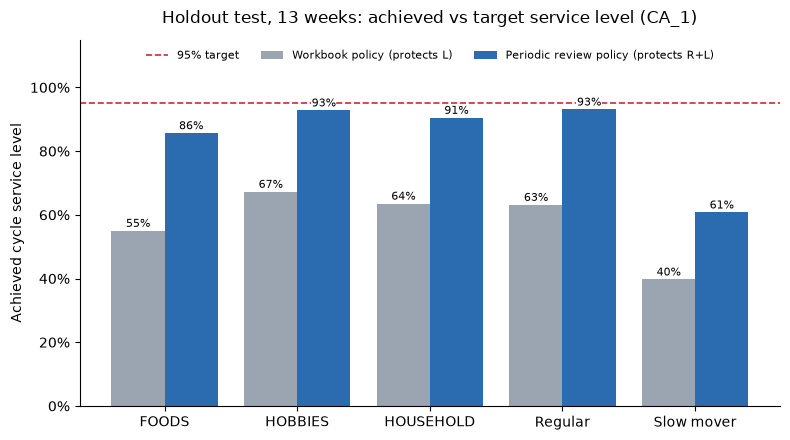

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
groups = list(by_cat.index) + ["Regular", "Slow mover"]
wb = list(by_cat[("Workbook (protects L)", "CSL")]) + list(by_type[("Workbook (protects L)", "CSL")])
rl = list(by_cat[("Periodic review (protects R+L)", "CSL")]) + list(by_type[("Periodic review (protects R+L)", "CSL")])
x = np.arange(len(groups))
ax.bar(x - 0.2, wb, 0.4, label="Workbook policy (protects L)", color="#9aa5b1")
ax.bar(x + 0.2, rl, 0.4, label="Periodic review policy (protects R+L)", color="#2b6cb0")
ax.axhline(CSL_TARGET, color="#c53030", ls="--", lw=1.2, label="95% target")
for xi, v in zip(x - 0.2, wb):
    ax.text(xi, v + 0.012, f"{v:.0%}", ha="center", fontsize=8, bbox=dict(fc="white", ec="none", pad=0.5))
for xi, v in zip(x + 0.2, rl):
    ax.text(xi, v + 0.012, f"{v:.0%}", ha="center", fontsize=8, bbox=dict(fc="white", ec="none", pad=0.5))
ax.set_xticks(x, groups)
ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Achieved cycle service level")
ax.set_title("Holdout test, 13 weeks: achieved vs target service level (CA_1)", pad=12)
ax.legend(loc="upper center", ncol=3, fontsize=8, frameon=False, bbox_to_anchor=(0.5, 1.0))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / f"holdout_csl_{STORE_ID}.png", dpi=150)
plt.show()

## 7. What the fix costs, and is the starting point driving the result?

- **Safety stock $:** planned buffer value, $SS \times C$.
- **Simulated avg inventory $:** average on-hand units over the 13 weeks (midpoint of each week) times unit cost. This is what the policy actually held, not the plan.
- **Annual holding cost $:** simulated average inventory $\times$ holding rate $h$ (25% per year).
- **Start sensitivity:** rerun both policies starting at $ROP + Q$ (as if an order had just arrived) instead of $SS + Q/2$.

In [10]:
def money(res, ss):
    return pd.Series({
        "Safety stock $": (ss[active] * C[active]).sum(),
        "Simulated avg inventory $": (res["avg_inv_units"] * res["unit_cost"]).sum(),
        "Annual holding cost $ (h x avg inventory)": HOLD_RATE * (res["avg_inv_units"] * res["unit_cost"]).sum(),
    })

cost = pd.DataFrame({"Workbook (protects L)": money(res_wb, ss_wb),
                     "Periodic review (protects R+L)": money(res_rl, ss_rl)})
cost["Change"] = cost.iloc[:, 1] / cost.iloc[:, 0] - 1
display(cost.style.format({cost.columns[0]: "${:,.0f}", cost.columns[1]: "${:,.0f}", "Change": "{:+.1%}"}))

alt_start = pd.concat({
    "Workbook, start SS+Q/2": summarize(res_wb),
    "Workbook, start ROP+Q": summarize(run(rop_wb, ss_wb, start=np.round(rop_wb + Q_units))),
    "R+L, start SS+Q/2": summarize(res_rl),
    "R+L, start ROP+Q": summarize(run(rop_rl, ss_rl, start=np.round(rop_rl + Q_units))),
}).droplevel(1)
alt_start.style.format(fmt)

,Workbook (protects L),Periodic review (protects R+L),Change
Safety stock $,"$53,923","$76,258",+41.4%
Simulated avg inventory $,"$143,711","$220,985",+53.8%
Annual holding cost $ (h x avg inventory),"$35,928","$55,246",+53.8%


,cycles,CSL,fill_rate
"Workbook, start SS+Q/2","7,770",60.0%,90.8%
"Workbook, start ROP+Q","5,877",58.3%,92.2%
"R+L, start SS+Q/2","8,900",88.5%,97.2%
"R+L, start ROP+Q","6,324",86.6%,97.5%


## 8. Export per-SKU results

In [11]:
out = res_wb[["item_id", "cat_id", "slow_mover_flag", "demand"]].copy()
for tag, r in [("wb", res_wb), ("rl", res_rl)]:
    out[f"lost_{tag}"] = r["lost"].round(0)
    out[f"cycles_{tag}"] = r["cycles"]
    out[f"stockout_cycles_{tag}"] = r["stockout_cycles"]
    out[f"avg_inv_units_{tag}"] = r["avg_inv_units"].round(2)
out.to_csv(DATA_DIR / f"holdout_results_{STORE_ID}.csv", index=False)
print(f"Saved {len(out):,} SKU rows to data/holdout_results_{STORE_ID}.csv")

Saved 2,708 SKU rows to data/holdout_results_CA_1.csv


## Reading the results

**1. The workbook policy, as built, misses the target by a wide margin.**
- Achieved cycle service level: 60.0% vs the 95% target (7,770 replenishment cycles over 2,708 SKUs). Fill rate: 90.8%.
- Every category misses: FOODS 55.0%, HOUSEHOLD 63.5%, HOBBIES 67.3%.

**2. The cause is the policy design, not bad luck in the data.**
- The workbook uses the continuous review formula, which only buffers the lead time $L$. A store reviews weekly, so stock has to last $R + L$ = 2 weeks.
- Proof: even on synthetic demand that follows the formula's own assumptions, the workbook policy reaches only 69.8% on regular SKUs.

**3. Sizing for $R + L$ gets regular SKUs close to target.**
- Periodic review policy: 88.5% CSL overall, 93.1% on regular SKUs (fill rate 98.6%).
- On synthetic normal demand the same policy reaches 98.2%, so the simulator and formula work when the assumptions hold. The remaining gap of about 2 points on regular SKUs comes from real demand:
  - Holdout demand ran 3.4% above the planning forecast overall, and 5.7% above for FOODS, the lowest category at 85.7%. The forecast $\bar{d}$ is static for the quarter, so the policy did not adjust.
  - Real weekly demand is lumpier than a normal distribution.

**4. Slow movers need a different method.**
- Even with the fix: 60.8% CSL and 74.5% fill rate for the 338 slow movers. The normal-error formula does not fit items that sell 0 to 2 units most weeks. This confirms the Step 1 flag.

**5. Hitting the target costs real money.**
- Safety stock: $53,923 to $76,258 (+41.4%, exactly $\sqrt{2}$, as the Step 3 sweep showed for a 2-week lead time).
- Simulated average inventory: $143,711 to $220,985 (+53.8%). It rises more than safety stock because the reorder point also adds one more week of expected demand.
- Annual holding cost at 25%: $35,928 to $55,246 (+$19,318 per year).

**6. The conclusion does not depend on the starting inventory.**
- Starting at $ROP + Q$ instead of $SS + Q/2$ moves CSL by under 2 points for both policies.